<style>
.jp-Notebook .jp-MarkdownCell,
.text_cell_render {
    font-size: 14px;
    line-height: 1.38;
}
.jp-CodeCell .cm-editor,
.jp-CodeCell pre,
.code_cell .CodeMirror {
    font-size: 13px !important;
    line-height: 1.30 !important;
}
</style>

# ECON 422: Macroeconomics & Machine Learning
## Time-Series Forecasting

**Goal:** Forecast next month's inflation using a classical AR model, two machine-learning (ML) models, and **Super Learner**. Then try a **sequential ML + ML hybrid**.

The data are simulated for teaching. The variable `news_signal` stands in for a numerical indicator *already extracted* from economic text (for example, by an LLM); this notebook does **not** run an LLM.

We predict

$$
\pi_{t+1}=f(\pi_t,\,u_t,\,i_t,\,s_t)+\varepsilon_{t+1},
$$

where $u_t$ is unemployment, $i_t$ is the policy rate, and $s_t$ is the news signal. All predictors refer to the **forecast origin** $t$, not the future outcome month $t+1$.

*Requires:* `numpy`, `pandas`, `matplotlib`, and `scikit-learn`. No downloads or API keys are needed.

### Setup and supplied data

Run the imports below. Next, **copy and paste the DGP code provided by your instructor** into the empty cell. It must create a pandas DataFrame named `df` with columns `month`, `inflation`, `unemployment`, `policy_rate`, `news_signal`, and `inflation_next`.

The DGP is deliberately **not included** in this student version.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

In [4]:
# Copy and paste the codes from Quizzies '[Week9] (Oct21) Exercise'.
# Simulated monthly data: all predictors at month t, outcome at t+1.
rng = np.random.default_rng(8)
n = 240
inflation = np.zeros(n)
unemployment = np.zeros(n)
policy_rate = np.zeros(n)
news_signal = np.zeros(n)
inflation[0], unemployment[0], policy_rate[0] = 2.0, 5.0, 3.0

for t in range(1, n):
    unemployment[t] = 5 + 0.75 * (unemployment[t-1] - 5) + rng.normal(0, 0.4)
    policy_rate[t] = 3 + 0.70 * (policy_rate[t-1] - 3) + rng.normal(0, 0.5)
    news_signal[t] = 0.50 * news_signal[t-1] + rng.normal(0, 0.8)
    inflation[t] = (0.62 * inflation[t-1] + 0.70 + 0.65 * max(news_signal[t-1], 0) + 0.15 * (unemployment[t-1] - 5)**2 - 0.13 * (policy_rate[t-1] - 3) + rng.normal(0, 0.30))

df = pd.DataFrame({
"month": pd.date_range("2004-01-01", periods=n, freq="MS"),
"inflation": inflation,
"unemployment": unemployment,
"policy_rate": policy_rate,
"news_signal": news_signal,
})
df["inflation_next"] = df["inflation"].shift(-1)
df = df.dropna().reset_index(drop=True)
print(df[["month", "inflation", "inflation_next"]].head(3).to_string(index=False))

     month  inflation  inflation_next
2004-01-01   2.000000        1.834515
2004-02-01   1.834515        2.264879
2004-03-01   2.264879        2.475271


### Practice 1 — Split by time (not randomly)

We reserve **140 months for estimation**, **50 for validation** (learning Super Learner weights), and the remaining months for **testing**. Type the gray code in the blank code cell below.

The observations in `df` are ordered by month. The target is `inflation_next`, which refers to the inflation outcome one month after each row's predictors.

**Type the gray code in the blank cell below.**

<pre style="color:#8a8a8a;background:#f7f7f7;border:1px solid #e4e4e4;border-radius:5px;padding:9px 11px;margin:6px 0 8px 0;font-family:Menlo, Monaco, Consolas, 'Courier New', monospace;font-size:12.5px;line-height:1.32;white-space:pre;overflow-x:auto;">features = [&quot;inflation&quot;, &quot;unemployment&quot;, &quot;policy_rate&quot;, &quot;news_signal&quot;]
train = df.iloc[:140].copy()
val = df.iloc[140:190].copy()
test = df.iloc[190:].copy()

print(&quot;Estimation / validation / test:&quot;, len(train), len(val), len(test))
print(&quot;Validation origins:&quot;, val.month.iloc[0].date(), &quot;to&quot;, val.month.iloc[-1].date())
plt.plot(df[&quot;month&quot;], df[&quot;inflation&quot;])
plt.title(&quot;Simulated monthly inflation&quot;)
plt.ylabel(&quot;Inflation (%)&quot;)
plt.show()</pre>

Estimation / validation / test: 140 50 49
Validation origins: 2015-09-01 to 2019-10-01


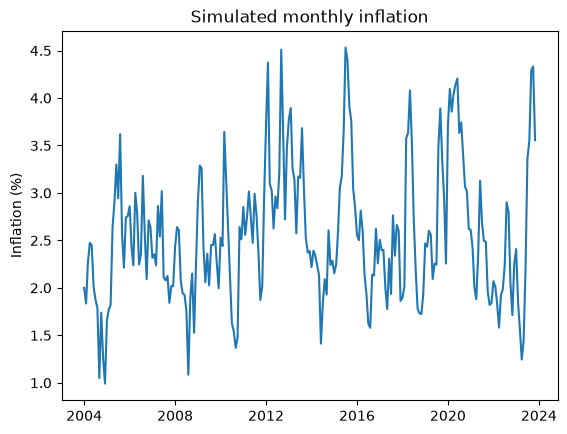

In [5]:
# Type Practice 1 here.
features = ["inflation", "unemployment", "policy_rate", "news_signal"]
train = df.iloc[:140].copy()
val = df.iloc[140:190].copy()
test = df.iloc[190:].copy()

print("Estimation / validation / test:", len(train), len(val), len(test))
print("Validation origins:", val.month.iloc[0].date(), "to", val.month.iloc[-1].date())
plt.plot(df["month"], df["inflation"])
plt.title("Simulated monthly inflation")
plt.ylabel("Inflation (%)")
plt.show()

### Practice 2 — Fit an AR benchmark and two ML models

The **AR(1)** benchmark forecasts inflation using only its most recent value. The **Random Forest (RF)** and **Gradient Boosting (GB)** models use all four predictors, including the simulated news indicator.

Fit all three models on the estimation sample. Then generate forecasts for the validation and test periods.

**Type the gray code in the blank cell below.**

<pre style="color:#8a8a8a;background:#f7f7f7;border:1px solid #e4e4e4;border-radius:5px;padding:9px 11px;margin:6px 0 8px 0;font-family:Menlo, Monaco, Consolas, 'Courier New', monospace;font-size:12.5px;line-height:1.32;white-space:pre;overflow-x:auto;">ar = LinearRegression().fit(train[[&quot;inflation&quot;]], train[&quot;inflation_next&quot;])
rf = RandomForestRegressor(n_estimators=100, max_depth=5,
                           min_samples_leaf=3, random_state=0)
gb = GradientBoostingRegressor(n_estimators=90, max_depth=2,
                               learning_rate=0.06, random_state=0)
rf.fit(train[features], train[&quot;inflation_next&quot;])
gb.fit(train[features], train[&quot;inflation_next&quot;])

rf_val, gb_val = rf.predict(val[features]), gb.predict(val[features])
rf_test, gb_test = rf.predict(test[features]), gb.predict(test[features])
ar_test = ar.predict(test[[&quot;inflation&quot;]])</pre>

In [6]:
# Type Practice 2 here.
ar = LinearRegression().fit(train[["inflation"]], train["inflation_next"])
rf = RandomForestRegressor(n_estimators=100, max_depth=5,
                           min_samples_leaf=3, random_state=0)
gb = GradientBoostingRegressor(n_estimators=90, max_depth=2,
                               learning_rate=0.06, random_state=0)
rf.fit(train[features], train["inflation_next"])
gb.fit(train[features], train["inflation_next"])

rf_val, gb_val = rf.predict(val[features]), gb.predict(val[features])
rf_test, gb_test = rf.predict(test[features]), gb.predict(test[features])
ar_test = ar.predict(test[["inflation"]])

### Practice 3 — Estimate Super Learner weights

Super Learner combines two independently generated ML forecasts:

$$
\hat\pi_{t+1\mid t}^{\mathrm{SL}}
=\hat w_{\mathrm{RF}}\hat\pi_{t+1\mid t}^{\mathrm{RF}}
+(1-\hat w_{\mathrm{RF}})\hat\pi_{t+1\mid t}^{\mathrm{GB}}.
$$

Its weights are learned from **historical validation forecasts**, not from the test data. Just like OLS without an intercept, define

$$
a_s=\pi_{s+1}-\hat\pi_{s+1\mid s}^{\mathrm{GB}},\qquad
b_s=\hat\pi_{s+1\mid s}^{\mathrm{RF}}-\hat\pi_{s+1\mid s}^{\mathrm{GB}},
\qquad
\hat w_{\mathrm{RF}}=\operatorname{clip}\!\left(
\frac{\sum_s a_s b_s}{\sum_s b_s^2},\,0,\,1\right).
$$

Here `clip` ensures that the RF weight lies between zero and one. (The GB weight is the remainder.)

**Type the gray code in the blank cell below.**

<pre style="color:#8a8a8a;background:#f7f7f7;border:1px solid #e4e4e4;border-radius:5px;padding:9px 11px;margin:6px 0 8px 0;font-family:Menlo, Monaco, Consolas, 'Courier New', monospace;font-size:12.5px;line-height:1.32;white-space:pre;overflow-x:auto;">a = val[&quot;inflation_next&quot;].to_numpy() - gb_val
b = rf_val - gb_val
w_rf = float(np.clip(np.sum(a * b) / np.sum(b**2), 0, 1))
w_gb = 1 - w_rf
sl_test = w_rf * rf_test + w_gb * gb_test
print(f&quot;Super Learner weights: RF = {w_rf:.3f}, GB = {w_gb:.3f}&quot;)</pre>

In [7]:
# Type Practice 3 here.
a = val["inflation_next"].to_numpy() - gb_val
b = rf_val - gb_val
w_rf = float(np.clip(np.sum(a * b) / np.sum(b**2), 0, 1))
w_gb = 1 - w_rf
sl_test = w_rf * rf_test + w_gb * gb_test
print(f"Super Learner weights: RF = {w_rf:.3f}, GB = {w_gb:.3f}")

Super Learner weights: RF = 0.272, GB = 0.728


### Practice 4 — Evaluate forecasts on the later test period

A good model should predict **future observations that it did not use for training or weight selection**. Use root mean squared error (RMSE):

$$
\mathrm{RMSE}=\sqrt{\frac{1}{N_{\mathrm{test}}}
\sum_{s\in\mathrm{test}}\left(\pi_{s+1}-\hat\pi_{s+1\mid s}\right)^2}.
$$

Compare AR, RF, GB, and Super Learner. The Super Learner is **not guaranteed** to beat every model in the test period.

**Type the gray code in the blank cell below.**

<pre style="color:#8a8a8a;background:#f7f7f7;border:1px solid #e4e4e4;border-radius:5px;padding:9px 11px;margin:6px 0 8px 0;font-family:Menlo, Monaco, Consolas, 'Courier New', monospace;font-size:12.5px;line-height:1.32;white-space:pre;overflow-x:auto;">def rmse(actual, predicted):
    return np.sqrt(np.mean((np.asarray(actual) - np.asarray(predicted))**2))

y_test = test[&quot;inflation_next&quot;].to_numpy()
for name, pred in {&quot;AR&quot;: ar_test, &quot;RF&quot;: rf_test,
                   &quot;GB&quot;: gb_test, &quot;Super Learner&quot;: sl_test}.items():
    print(f&quot;{name:13s} RMSE: {rmse(y_test, pred):.3f}&quot;)

plt.plot(test[&quot;month&quot;], y_test, label=&quot;Actual next-month inflation&quot;)
plt.plot(test[&quot;month&quot;], sl_test, label=&quot;Super Learner&quot;)
plt.title(&quot;Out-of-sample inflation forecasts&quot;)
plt.legend()
plt.show()</pre>

AR            RMSE: 0.475
RF            RMSE: 0.353
GB            RMSE: 0.357
Super Learner RMSE: 0.352


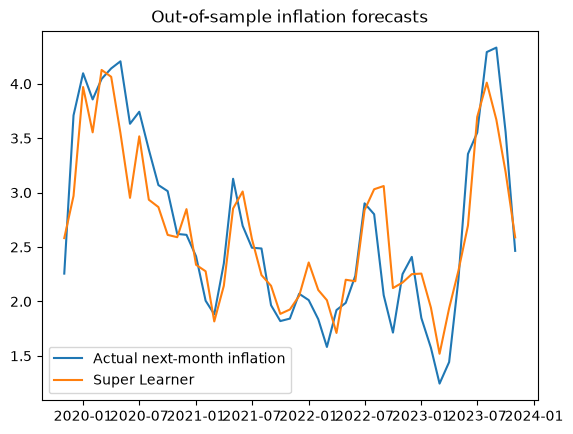

In [8]:
# Type Practice 4 here.
def rmse(actual, predicted):
    return np.sqrt(np.mean((np.asarray(actual) - np.asarray(predicted))**2))

y_test = test["inflation_next"].to_numpy()
for name, pred in {"AR": ar_test, "RF": rf_test,
                   "GB": gb_test, "Super Learner": sl_test}.items():
    print(f"{name:13s} RMSE: {rmse(y_test, pred):.3f}")

plt.plot(test["month"], y_test, label="Actual next-month inflation")
plt.plot(test["month"], sl_test, label="Super Learner")
plt.title("Out-of-sample inflation forecasts")
plt.legend()
plt.show()

**What did we learn?**

- **Super Learner** trains candidate models separately and estimates **combination weights** from historical validation errors.
- A **sequential hybrid** first fits a baseline model, then fits a second model to its historical forecast errors.
- A **joint additive model** (not coded here) would train two components simultaneously under one prediction loss, for example $\hat\pi=f_{\theta_1}(\text{macro data})+g_{\theta_2}(\text{news signals})$.
- **Estimation sample $\rightarrow$ validation period $\rightarrow$ test period:** preserve time ordering throughout. Prediction accuracy alone does not establish a causal relationship.

### Exercise — Sequential hybrid forecasting: ML + ML (10 points)

Now let two ML models work **sequentially**:

1. **RF** provides a baseline inflation forecast.
2. **GB** learns the residual errors left by RF on historical validation dates.
3. Add the GB correction to the RF forecast for the test period.

$$
\hat\pi_{t+1\mid t}^{\mathrm{hybrid}}
=\underbrace{\hat\pi_{t+1\mid t}^{\mathrm{RF}}}_{\text{baseline}}
+\underbrace{\hat r_{t+1\mid t}^{\mathrm{GB}}}_{\text{predicted error correction}}.
$$

**Hints** (fill the blanks in the code cell below):

- **Residuals.** Calculate *actual validation inflation minus the RF validation forecast*. These RF validation predictions are out of sample relative to RF's training data.
- **Correction model.** Train a new GB model with validation-period predictors as inputs and RF forecast errors as targets; do not use test outcomes to fit it.
- **Hybrid forecast.** Predict the correction on test-period predictors, then **add** it to RF's test forecast.
- **Evaluation.** Report RF and hybrid test RMSEs, and explain in one or two sentences whether the correction helped on this simulated test period.

In [ ]:
# Exercise: complete the blanks. Use variables from Practices 1–4.
rf_errors_val = val["inflation_next"].to_numpy() - rf_val

correction_gb = GradientBoostingRegressor(
    n_estimators=45, max_depth=1, learning_rate=0.05, random_state=0
)
correction_gb.fit(val[features], rf_errors_val)

correction_test = correction_gb.predict(test[features])
hybrid_test = rf_test + correction_test

print("RF RMSE:", round(rmse(y_test, rf_test), 3))
print("Hybrid RMSE:", round(rmse(y_test, hybrid_test), 3))
# After using the hybrid method, the root mean squared error of the random forest method decreased from 0.353 to 0.337, meaning that adding the predicted
# error correction did help in making the model more effective.

RF RMSE: 0.353
Hybrid RMSE: 0.337
